In [4]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import pandas as pd
from itertools import islice
import glob


file_path = Path.cwd()
tactile_data_path = file_path.parent / "tactile_data"

material_labels = ["aluminum_board","outer_pigskin","back_pigskin","cork","denim","rubber_board","Japanese_paper","wood_board"]

tracing_speed = [20,30,40,50,60,70,80,90,100]

START = 3000
END = 8000
NROWS = END - START

dt_data = 0.1 * 1e-3

print("file_path:", file_path)
print("tactile_data_path:", tactile_data_path)

file_path: c:\Users\haru4\研究\研究コード\いろいろ
tactile_data_path: c:\Users\haru4\研究\研究コード\tactile_data


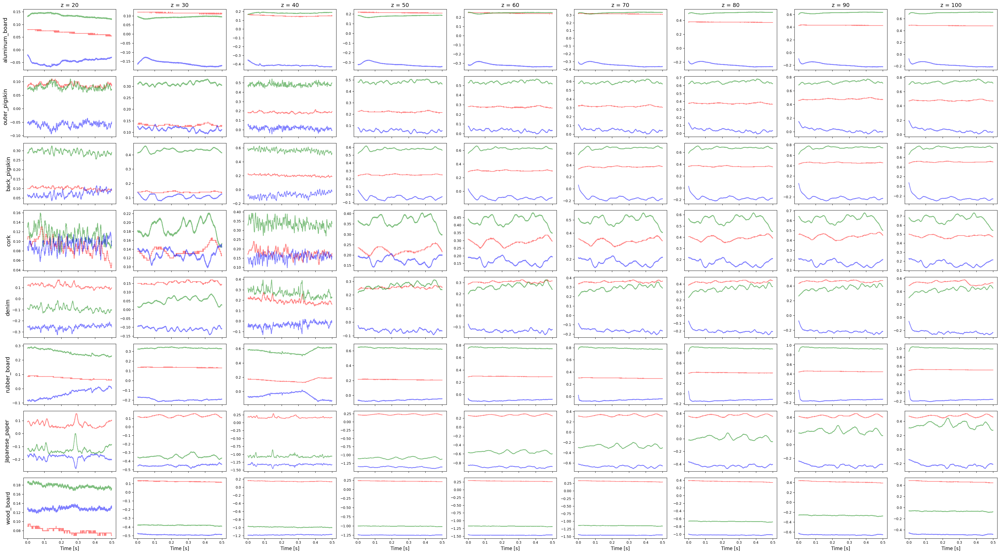

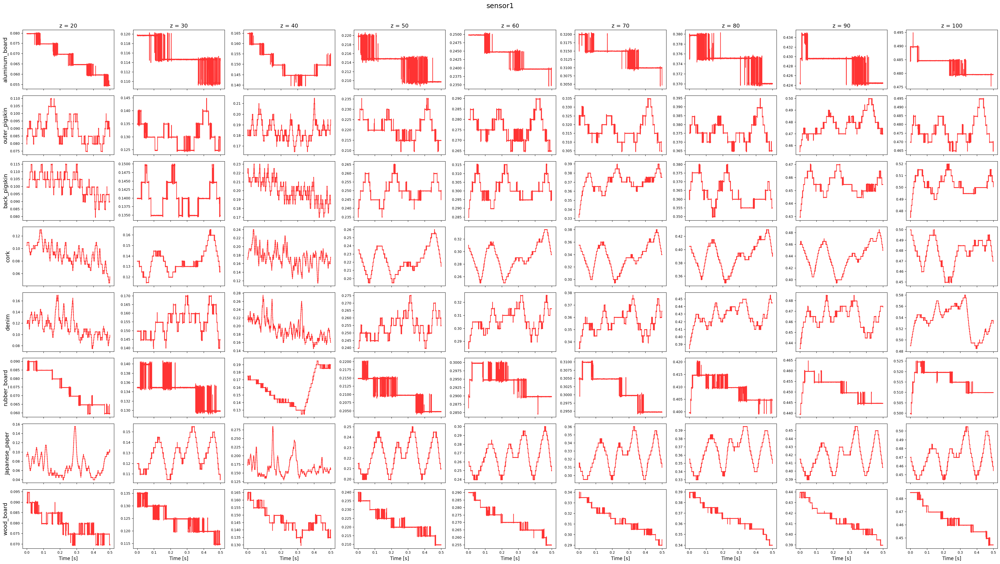

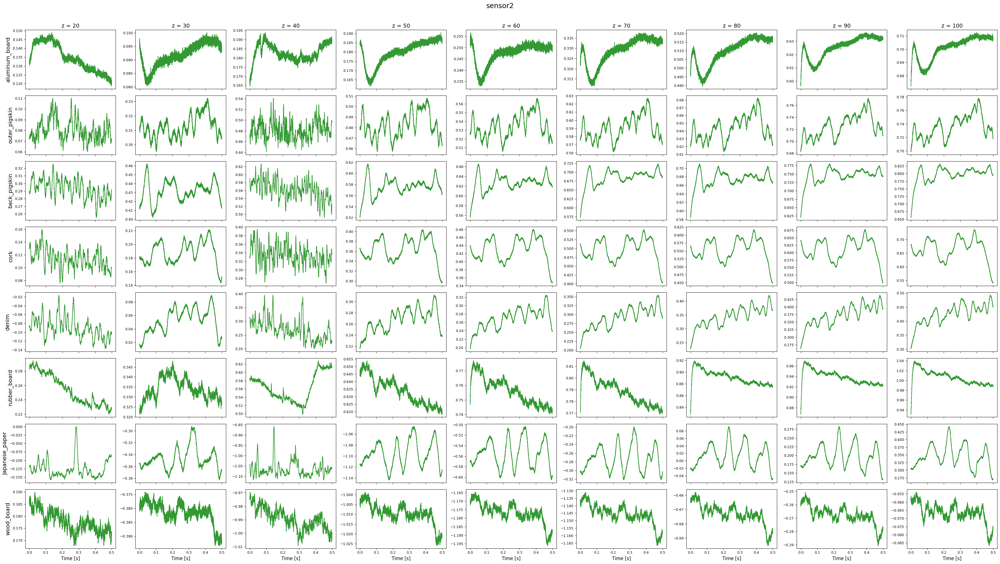

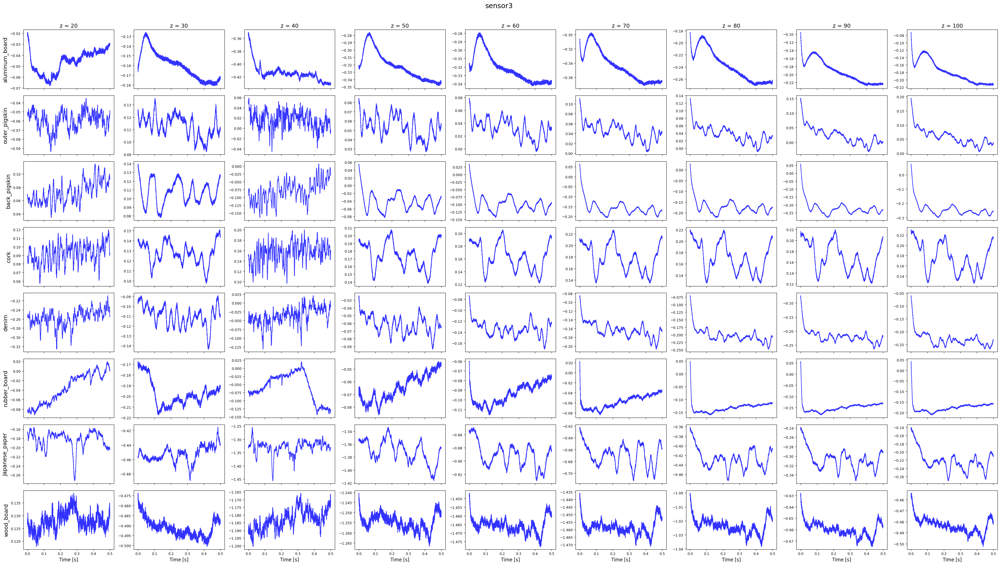

In [5]:
fig, axes = plt.subplots(len(material_labels), len(tracing_speed), figsize=(4 * len(tracing_speed), 2.5 * len(material_labels)),squeeze=False,sharex=True)

clr = ["r", "g", "b"]
NUM_SAMPLE = 1

for i, material in enumerate(material_labels):
    for j, speed in enumerate(tracing_speed):

        ax = axes[i, j]

        file_iter = (tactile_data_path / material).glob(
            f"data_*_x*_z{speed}_p*.csv"
        )

        file_list = list(islice(file_iter, NUM_SAMPLE))

        for file_path_csv in file_list:

            df = pd.read_csv(file_path_csv,header=None,sep=None,engine="python",skiprows=START,nrows=NROWS,usecols=[0, 1, 2])

            
            in_data_0 = df.to_numpy().T
            nt = in_data_0.shape[1]
            t_array = np.arange(nt) * dt_data

            for s in range(3):
                ax.plot(t_array,in_data_0[s],color=clr[s],alpha=0.5)

        # 一番上だけ速さを書く
        if i == 0:
            ax.set_title(f"z = {speed}", fontsize=14)

        # 一番左だけ素材名を書く
        if j == 0:
            ax.set_ylabel(material, fontsize=14)

        # 一番下だけx軸ラベルを書く
        if i == len(material_labels) - 1:
            ax.set_xlabel("Time [s]", fontsize=12)

        ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

# 各センサーだけを個別に表示
sensor_names = ["sensor1", "sensor2", "sensor3"]

for s, sensor_name in enumerate(sensor_names):
    fig, axes = plt.subplots(
        len(material_labels),
        len(tracing_speed),
        figsize=(4 * len(tracing_speed), 2.5 * len(material_labels)),
        squeeze=False,
        sharex=True,
    )

    for i, material in enumerate(material_labels):
        for j, speed in enumerate(tracing_speed):
            ax = axes[i, j]

            file_iter = (tactile_data_path / material).glob(
                f"data_*_x*_z{speed}_p*.csv"
            )
            file_list = list(islice(file_iter, NUM_SAMPLE))

            for file_path_csv in file_list:
                df = pd.read_csv(
                    file_path_csv,
                    header=None,
                    sep=None,
                    engine="python",
                    skiprows=START,
                    nrows=NROWS,
                    usecols=[0, 1, 2],
                )

                in_data_0 = df.to_numpy().T
                nt = in_data_0.shape[1]
                t_array = np.arange(nt) * dt_data
                ax.plot(t_array, in_data_0[s], color=clr[s], alpha=0.8)

            if i == 0:
                ax.set_title(f"z = {speed}", fontsize=14)

            if j == 0:
                ax.set_ylabel(material, fontsize=14)

            if i == len(material_labels) - 1:
                ax.set_xlabel("Time [s]", fontsize=12)

            ax.tick_params(labelsize=9)

    fig.suptitle(sensor_name, fontsize=18, y=1.01)
    plt.tight_layout()
    plt.show()


In [6]:
# 差分フィルタを関数として定義
DERIVATIVE_WIDTH = 1
EMA_TAU_MS = 2.0


# 指数平滑フィルタ
def exponential_smoothing(data, dt=dt_data, tau_ms=EMA_TAU_MS):
    data = np.asarray(data, dtype=float)
    tau_s = tau_ms * 1e-3

    if data.ndim == 1:
        smoothed = np.empty_like(data)
        smoothed[0] = data[0]
        alpha = 1.0 - np.exp(-dt / tau_s)
        for i in range(1, data.shape[0]):
            smoothed[i] = smoothed[i - 1] + alpha * (data[i] - smoothed[i - 1])
        return smoothed

    return np.array([
        exponential_smoothing(data[s], dt=dt, tau_ms=tau_ms)
        for s in range(data.shape[0])
    ])


# 差分フィルタ
def _abs_derivative(data, t, i, width=DERIVATIVE_WIDTH):
    j = max(0, i - int(width))
    if j == i:
        return 0.0
    return np.abs(data[i] - data[j]) / (t[i] - t[j])


def apply_abs_derivative_filter(in_data, t_array, width=DERIVATIVE_WIDTH):
    return np.array([
        [_abs_derivative(in_data[s], t_array, k, width=width) for k in range(in_data.shape[1])]
        for s in range(in_data.shape[0])
    ])


def load_filtered_inputs(file_path_csv):
    df = pd.read_csv(
        file_path_csv,
        header=None,
        sep=None,
        engine="python",
        skiprows=START,
        nrows=NROWS,
        usecols=[0, 1, 2],
    )
    raw = df.to_numpy().T
    t_array = np.arange(raw.shape[1]) * dt_data
    abs_derivative = apply_abs_derivative_filter(raw, t_array)
    ema = exponential_smoothing(raw, dt=dt_data, tau_ms=EMA_TAU_MS)
    ema_abs_derivative = apply_abs_derivative_filter(ema, t_array)
    return t_array, raw, abs_derivative, ema, ema_abs_derivative


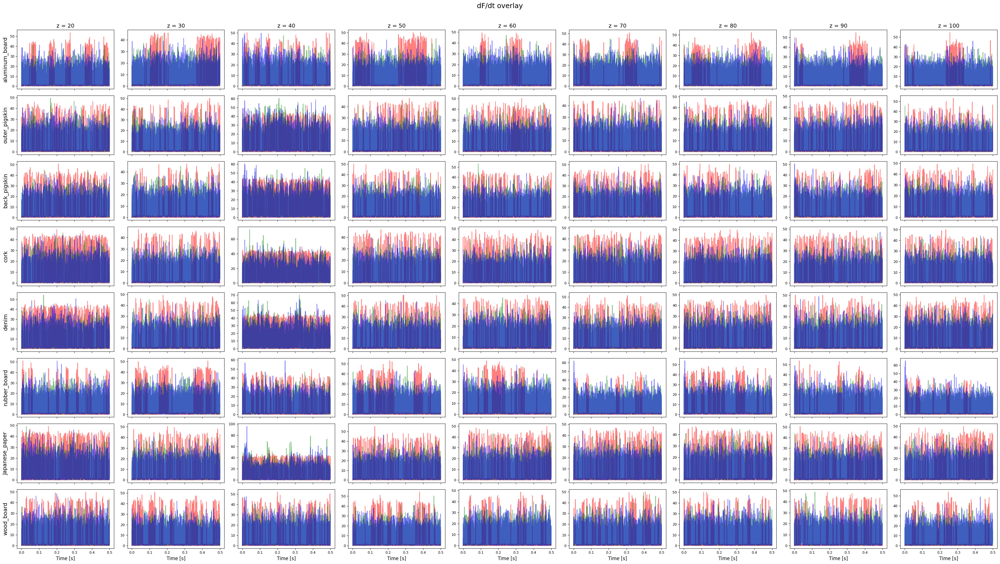

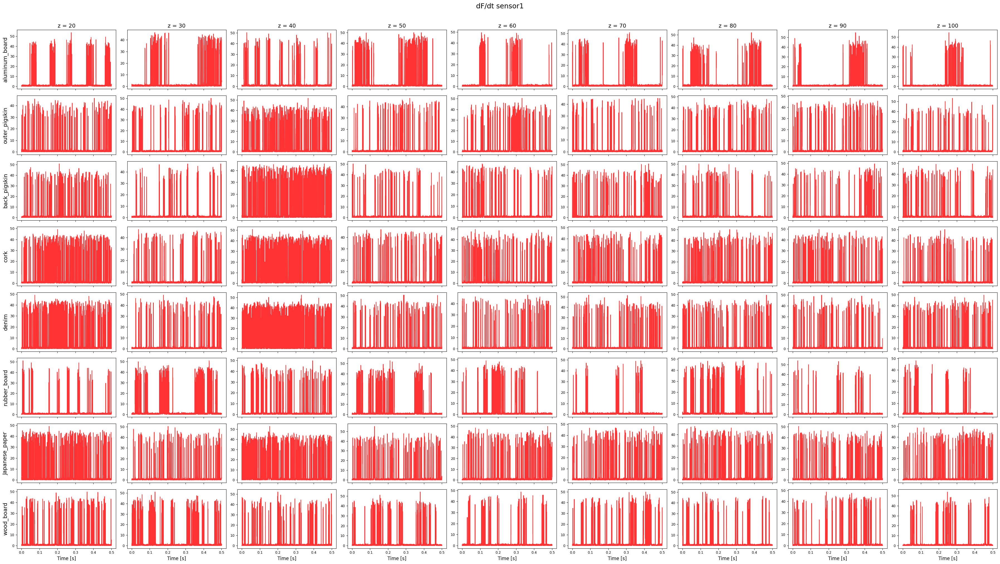

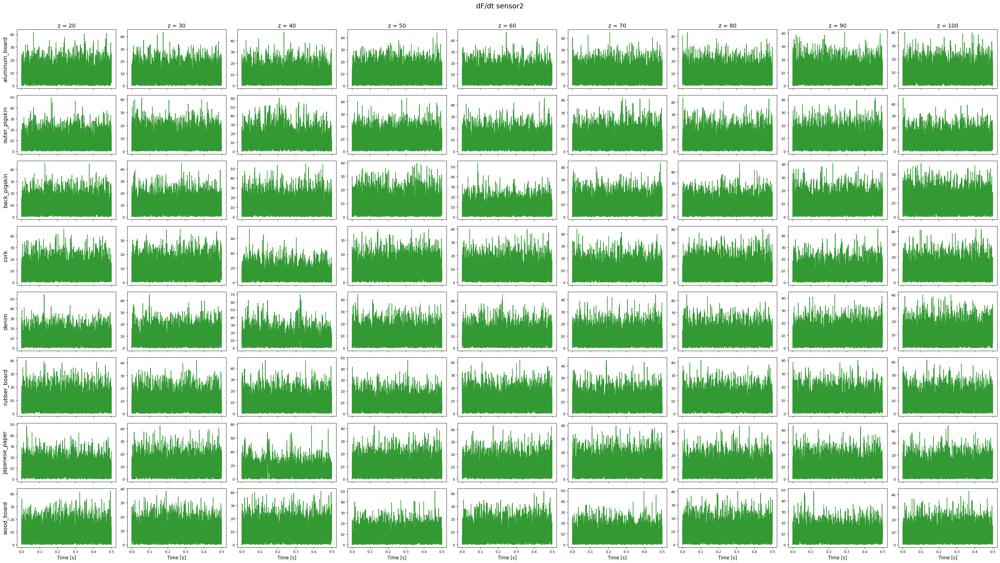

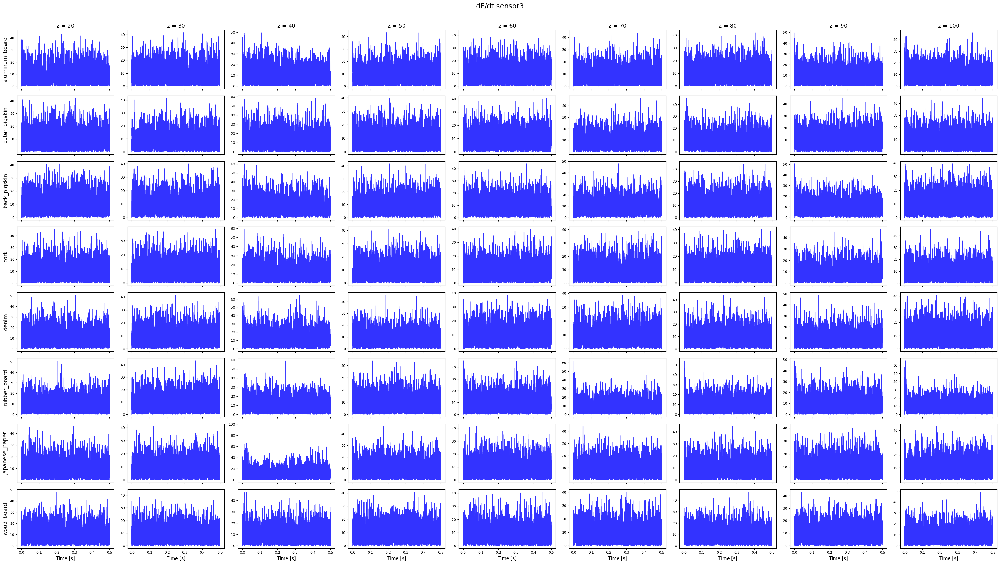

In [7]:
# 差分をとった結果を表示
# raw信号の1サンプル差分を dt_data で割って dF/dt として描画する

fig, axes = plt.subplots(
    len(material_labels),
    len(tracing_speed),
    figsize=(4 * len(tracing_speed), 2.5 * len(material_labels)),
    squeeze=False,
    sharex=True,
)

for i, material in enumerate(material_labels):
    for j, speed in enumerate(tracing_speed):
        ax = axes[i, j]

        file_iter = (tactile_data_path / material).glob(
            f"data_*_x*_z{speed}_p*.csv"
        )
        file_list = list(islice(file_iter, NUM_SAMPLE))

        for file_path_csv in file_list:
            df = pd.read_csv(
                file_path_csv,
                header=None,
                sep=None,
                engine="python",
                skiprows=START,
                nrows=NROWS,
                usecols=[0, 1, 2],
            )

            in_data_0 = df.to_numpy().T
            nt = in_data_0.shape[1]
            t_array = np.arange(nt) * dt_data
            diff_data = apply_abs_derivative_filter(in_data_0, t_array)

            for s in range(3):
                ax.plot(t_array, diff_data[s], color=clr[s], alpha=0.5)

        if i == 0:
            ax.set_title(f"z = {speed}", fontsize=14)

        if j == 0:
            ax.set_ylabel(material, fontsize=14)

        if i == len(material_labels) - 1:
            ax.set_xlabel("Time [s]", fontsize=12)

        ax.tick_params(labelsize=9)

fig.suptitle("dF/dt overlay", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

# 差分結果を各センサーだけで個別に表示
sensor_names = ["sensor1", "sensor2", "sensor3"]

for s, sensor_name in enumerate(sensor_names):
    fig, axes = plt.subplots(
        len(material_labels),
        len(tracing_speed),
        figsize=(4 * len(tracing_speed), 2.5 * len(material_labels)),
        squeeze=False,
        sharex=True,
    )

    for i, material in enumerate(material_labels):
        for j, speed in enumerate(tracing_speed):
            ax = axes[i, j]

            file_iter = (tactile_data_path / material).glob(
                f"data_*_x*_z{speed}_p*.csv"
            )
            file_list = list(islice(file_iter, NUM_SAMPLE))

            for file_path_csv in file_list:
                df = pd.read_csv(
                    file_path_csv,
                    header=None,
                    sep=None,
                    engine="python",
                    skiprows=START,
                    nrows=NROWS,
                    usecols=[0, 1, 2],
                )

                in_data_0 = df.to_numpy().T
                nt = in_data_0.shape[1]
                t_array = np.arange(nt) * dt_data
                diff_data = np.array([
                    [_abs_derivative(in_data_0[s], t_array, k) for k in range(nt)]
                    for s in range(in_data_0.shape[0])
                ])
                ax.plot(t_array, diff_data[s], color=clr[s], alpha=0.8)

            if i == 0:
                ax.set_title(f"z = {speed}", fontsize=14)

            if j == 0:
                ax.set_ylabel(material, fontsize=14)

            if i == len(material_labels) - 1:
                ax.set_xlabel("Time [s]", fontsize=12)

            ax.tick_params(labelsize=9)

    fig.suptitle(f"dF/dt {sensor_name}", fontsize=18, y=1.01)
    plt.tight_layout()
    plt.show()


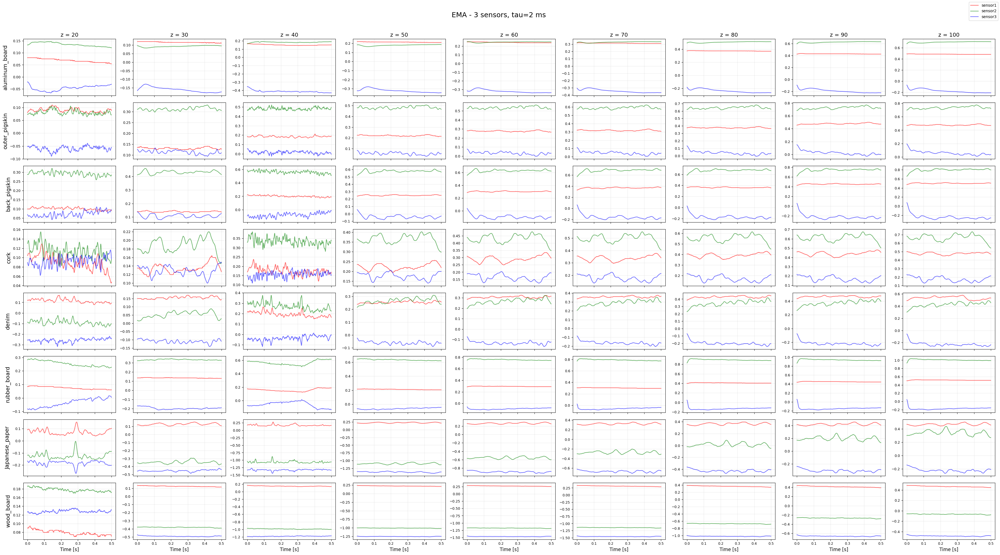

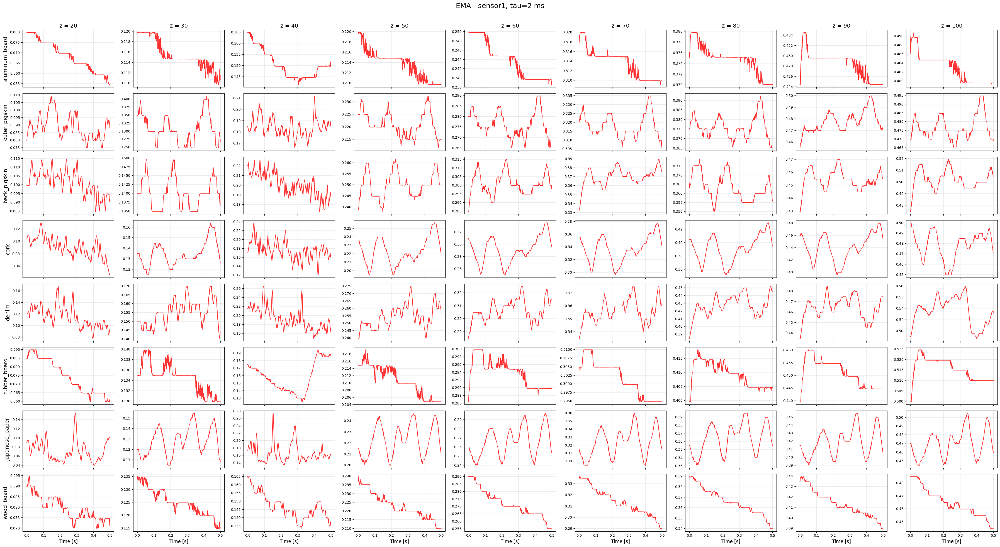

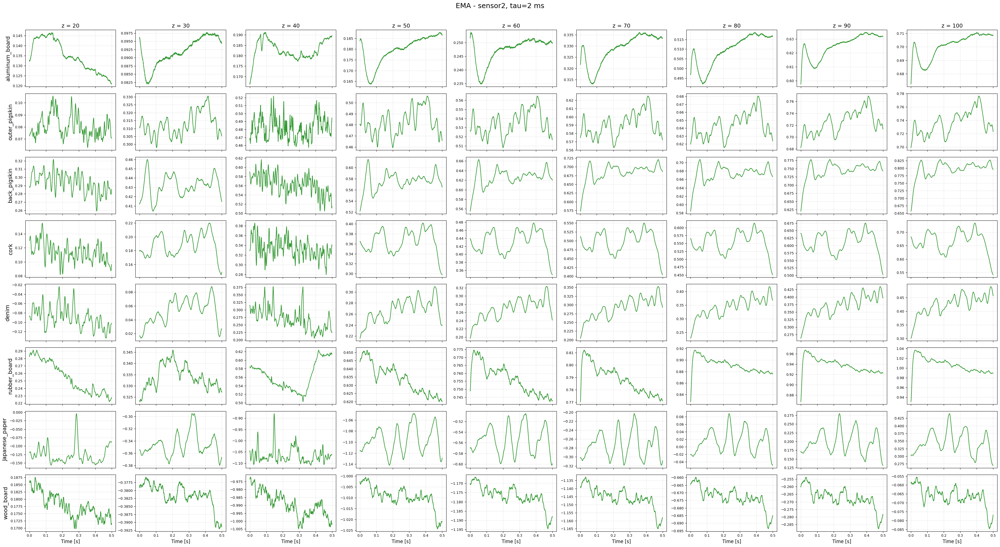

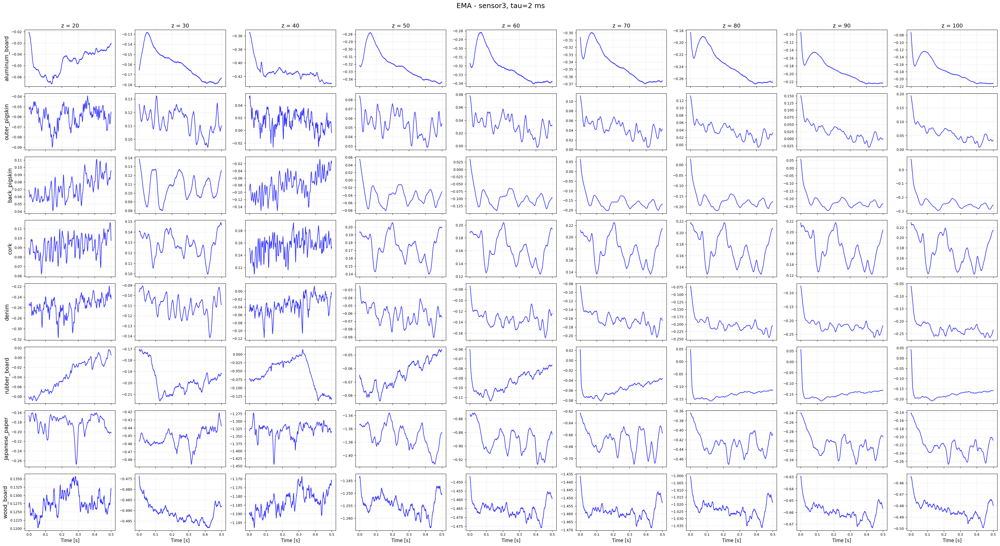

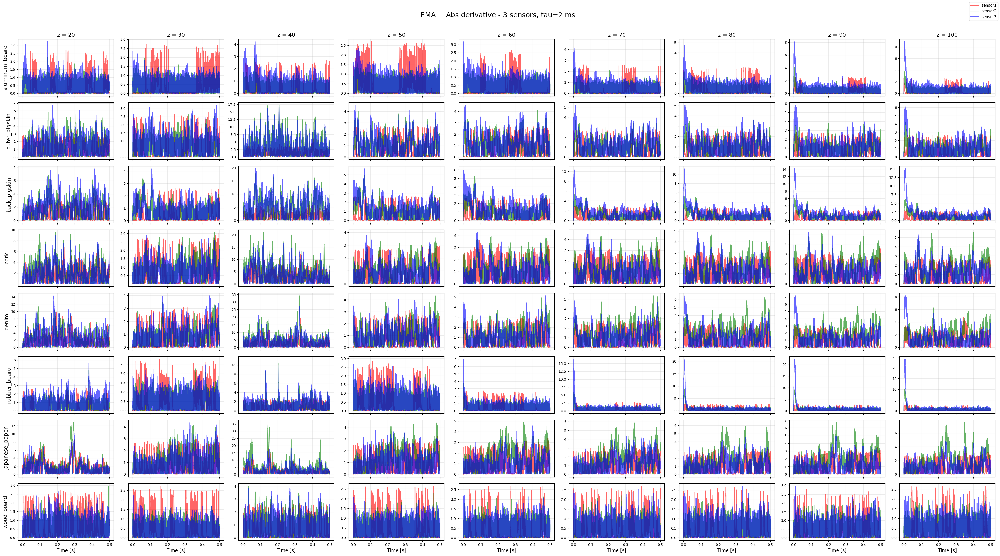

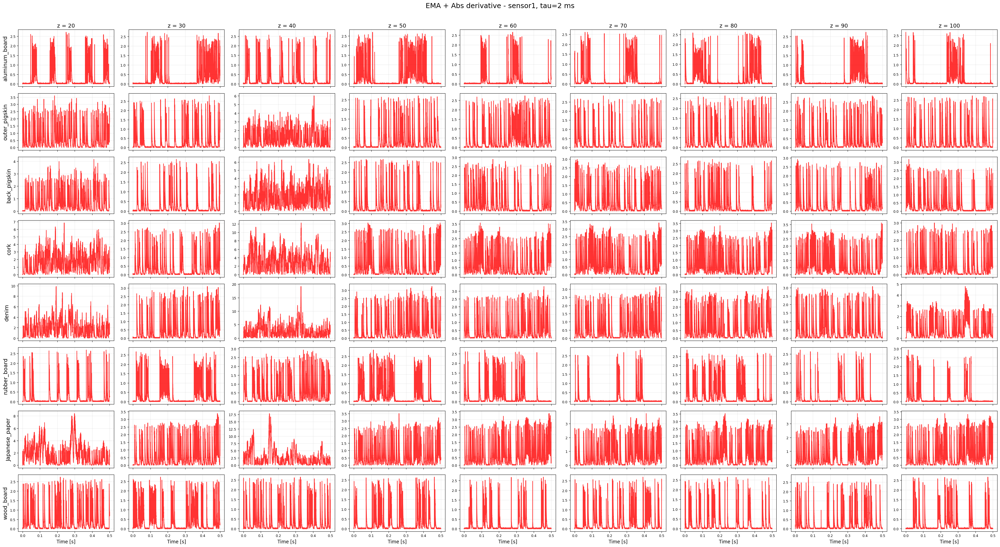

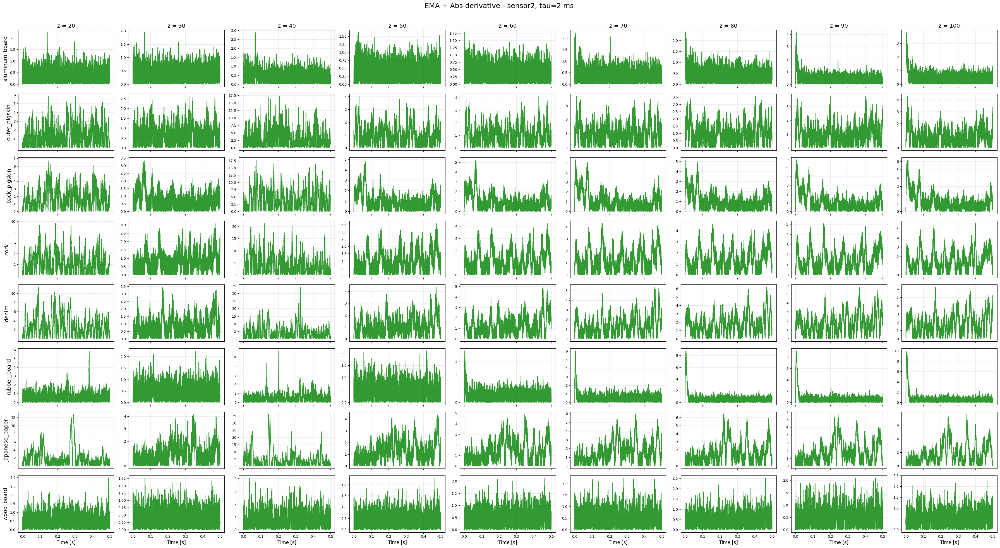

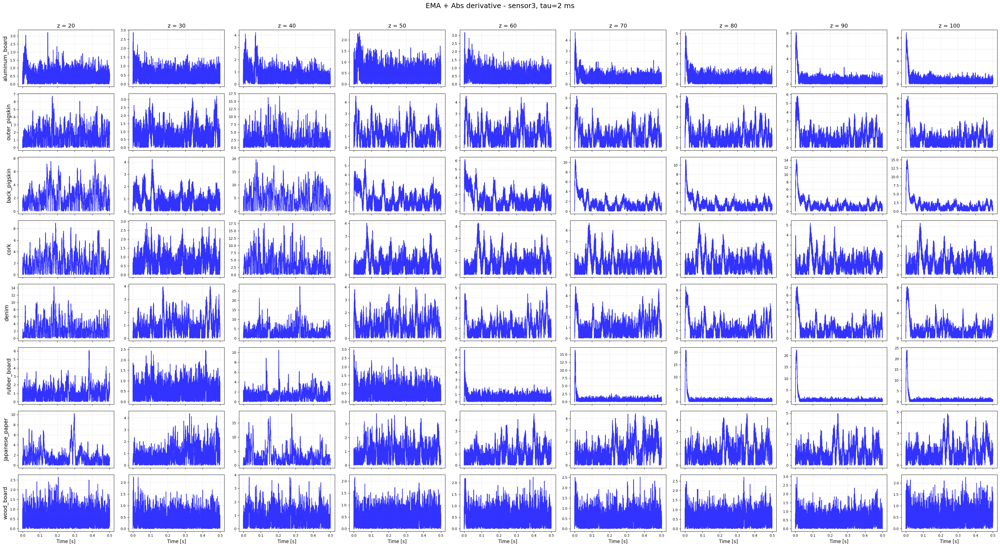

In [8]:
# 指数平滑後に差分をとった結果を表示

for filter_name in ["EMA", "EMA + Abs derivative"]:
    fig, axes = plt.subplots(
        len(material_labels),
        len(tracing_speed),
        figsize=(4 * len(tracing_speed), 2.5 * len(material_labels)),
        squeeze=False,
        sharex=True,
        sharey=False,
    )

    for i, material in enumerate(material_labels):
        for j, speed in enumerate(tracing_speed):
            ax = axes[i, j]
            file_list = list(islice(
                (tactile_data_path / material).glob(f"data_*_x*_z{speed}_p*.csv"),
                NUM_SAMPLE,
            ))

            if len(file_list) == 0:
                ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes)
            else:
                for file_path_csv in file_list:
                    t_array, raw, abs_derivative, ema, ema_abs_derivative = load_filtered_inputs(file_path_csv)
                    filtered = ema if filter_name == "EMA" else ema_abs_derivative
                    for sensor_id in range(3):
                        ax.plot(
                            t_array,
                            filtered[sensor_id],
                            color=clr[sensor_id],
                            alpha=0.6,
                            label=f"sensor{sensor_id + 1}" if i == 0 and j == 0 else None,
                        )

            if i == 0:
                ax.set_title(f"z = {speed}", fontsize=14)
            if j == 0:
                ax.set_ylabel(material, fontsize=14)
            if i == len(material_labels) - 1:
                ax.set_xlabel("Time [s]", fontsize=12)

            ax.tick_params(labelsize=9)
            ax.grid(True, alpha=0.25)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")
    fig.suptitle(f"{filter_name} - 3 sensors, tau={EMA_TAU_MS:g} ms", fontsize=18)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

    # 各センサーだけを個別に表示
    for sensor_id in range(3):
        fig, axes = plt.subplots(
            len(material_labels),
            len(tracing_speed),
            figsize=(4 * len(tracing_speed), 2.5 * len(material_labels)),
            squeeze=False,
            sharex=True,
            sharey=False,
        )

        for i, material in enumerate(material_labels):
            for j, speed in enumerate(tracing_speed):
                ax = axes[i, j]
                file_list = list(islice(
                    (tactile_data_path / material).glob(f"data_*_x*_z{speed}_p*.csv"),
                    NUM_SAMPLE,
                ))

                if len(file_list) == 0:
                    ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes)
                else:
                    for file_path_csv in file_list:
                        t_array, raw, abs_derivative, ema, ema_abs_derivative = load_filtered_inputs(file_path_csv)
                        filtered = ema if filter_name == "EMA" else ema_abs_derivative
                        ax.plot(t_array, filtered[sensor_id], color=clr[sensor_id], alpha=0.8)

                if i == 0:
                    ax.set_title(f"z = {speed}", fontsize=14)
                if j == 0:
                    ax.set_ylabel(material, fontsize=14)
                if i == len(material_labels) - 1:
                    ax.set_xlabel("Time [s]", fontsize=12)

                ax.tick_params(labelsize=9)
                ax.grid(True, alpha=0.25)

        fig.suptitle(f"{filter_name} - sensor{sensor_id + 1}, tau={EMA_TAU_MS:g} ms", fontsize=18)
        plt.tight_layout(rect=[0, 0, 1, 0.97])
        plt.show()


selected files: 800 / 2592


,material,selected_files
0,Japanese_paper,100
1,aluminum_board,100
2,back_pigskin,100
3,cork,100
4,denim,100
5,outer_pigskin,100
6,rubber_board,100
7,wood_board,100


,material,speed,path,file
0,aluminum_board,100,c:\Users\haru4\研究\研究コード\tactile_data\aluminum_...,data_296_x10000_z100_p1728.csv
1,aluminum_board,30,c:\Users\haru4\研究\研究コード\tactile_data\aluminum_...,data_66_x20000_z30_p1280.csv
2,aluminum_board,20,c:\Users\haru4\研究\研究コード\tactile_data\aluminum_...,data_24_x17500_z20_p1216.csv
3,aluminum_board,90,c:\Users\haru4\研究\研究コード\tactile_data\aluminum_...,data_275_x17500_z90_p1664.csv
4,aluminum_board,50,c:\Users\haru4\研究\研究コード\tactile_data\aluminum_...,data_141_x20000_z50_p1408.csv


,material,speed,tau_ms,file,s0_power_2_4Hz,s0_ratio_2_4Hz,s0_log_power_2_4Hz,s0_power_4_8Hz,s0_ratio_4_8Hz,s0_log_power_4_8Hz,...,s2_log_power_64_128Hz,s2_power_128_256Hz,s2_ratio_128_256Hz,s2_log_power_128_256Hz,s2_power_256_512Hz,s2_ratio_256_512Hz,s2_log_power_256_512Hz,s2_power_512_1024Hz,s2_ratio_512_1024Hz,s2_log_power_512_1024Hz
0,aluminum_board,100,0.0,data_296_x10000_z100_p1728.csv,564916.751589,0.002090,5.751984,1.375493e+06,0.005089,6.138458,...,7.166207,2.815248e+07,0.146191,7.449517,4.079852e+07,0.211860,7.610644,7.093556e+07,0.368356,7.850864
1,aluminum_board,100,0.5,data_296_x10000_z100_p1728.csv,55442.456072,0.001943,4.743842,3.896752e+05,0.013655,5.590703,...,6.556907,3.285188e+06,0.144584,6.516560,3.257255e+06,0.143354,6.512852,4.636042e+06,0.204036,6.666147
2,aluminum_board,100,1.0,data_296_x10000_z100_p1728.csv,26119.802103,0.002649,4.416970,2.089662e+05,0.021193,5.320076,...,6.026814,9.228902e+05,0.125473,5.965150,9.968851e+05,0.135534,5.998645,2.247989e+06,0.305630,6.351794
3,aluminum_board,100,1.5,data_296_x10000_z100_p1728.csv,16913.291757,0.003426,4.228228,1.196106e+05,0.024226,5.077770,...,5.698516,4.233017e+05,0.107769,5.626650,4.879382e+05,0.124225,5.688365,1.469565e+06,0.374138,6.167189
4,aluminum_board,100,2.0,data_296_x10000_z100_p1728.csv,12123.349660,0.004079,4.083623,7.511757e+04,0.025272,4.875742,...,5.473578,2.436497e+05,0.092477,5.386766,2.977970e+05,0.113029,5.473920,1.070559e+06,0.406331,6.029611


,split_id,tau_ms,feature,sensor_combo,accuracy,n_train,n_test
0,0,0.0,ratio,s0,0.541071,240,560
1,0,0.0,ratio,s1,0.483929,240,560
2,0,0.0,ratio,s2,0.410714,240,560
3,0,0.0,ratio,s0+s1+s2,0.753571,240,560
4,0,0.5,ratio,s0,0.682143,240,560
...,...,...,...,...,...,...,...
3355,19,9.5,log_power,s0+s1+s2,0.953571,240,560
3356,19,10.0,log_power,s0,0.826786,240,560
3357,19,10.0,log_power,s1,0.914286,240,560
3358,19,10.0,log_power,s2,0.871429,240,560


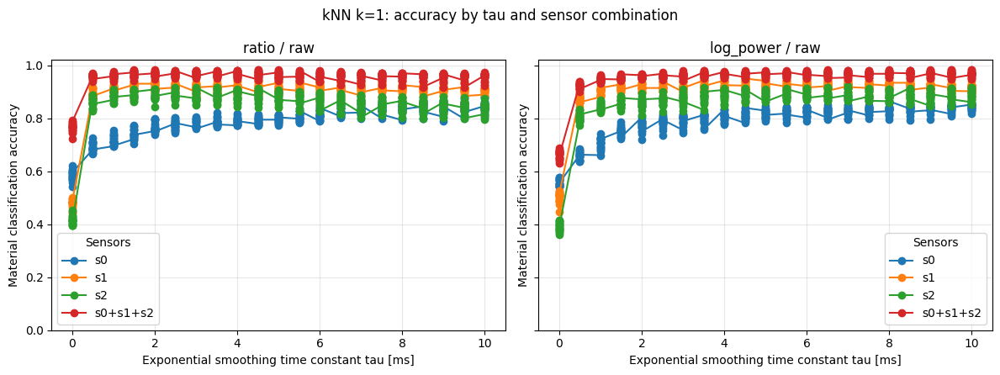

In [9]:
# 指数移動平均 + 差分フィルタ + FFT帯域特徴で分類
TAU_MS_LIST = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
FREQ_BANDS = [(2, 4), (4, 8), (8, 16), (16, 32), (32, 64), (64, 128), (128, 256), (256, 512), (512, 1024)]
SENSOR_COMBINATIONS = {
    "s0": [0],
    "s1": [1],
    "s2": [2],
    "s0+s1+s2": [0, 1, 2],
}
EPS = 1e-12
TRAIN_RATIO = 0.3
K_NEIGHBORS = 1
RANDOM_SEED = 0
N_SPLITS = 20
N_RANDOM_FILES_PER_MATERIAL = 100


def ema_filter(data, dt=dt_data, tau_ms=2.0):
    data = np.asarray(data, dtype=float)
    if tau_ms <= 0:
        return data.copy()

    tau_s = tau_ms * 1e-3
    alpha = 1.0 - np.exp(-dt / tau_s)

    if data.ndim == 1:
        out = np.empty_like(data)
        out[0] = data[0]
        for i in range(1, data.shape[0]):
            out[i] = alpha * data[i] + (1.0 - alpha) * out[i - 1]
        return out

    return np.array([ema_filter(data[s], dt=dt, tau_ms=tau_ms) for s in range(data.shape[0])])


def abs_derivative_signal(data, t_array, width=DERIVATIVE_WIDTH):
    data = np.asarray(data, dtype=float)
    if data.ndim == 1:
        return np.array([_abs_derivative(data, t_array, i, width=width) for i in range(data.shape[0])])

    return np.array([
        [_abs_derivative(data[s], t_array, i, width=width) for i in range(data.shape[1])]
        for s in range(data.shape[0])
    ])


def calc_power_spectrum(signal, dt=dt_data):
    signal = np.asarray(signal, dtype=float)
    signal = signal - np.mean(signal)
    freq = np.fft.rfftfreq(signal.shape[0], d=dt)
    spectrum = np.fft.rfft(signal)
    power = np.abs(spectrum) ** 2
    return freq, power


def band_power_features(filtered_abs_derivative, dt=dt_data, bands=FREQ_BANDS):
    powers_by_sensor = []
    ratios_by_sensor = []
    log_powers_by_sensor = []

    for sensor_id in range(filtered_abs_derivative.shape[0]):
        freq, power = calc_power_spectrum(filtered_abs_derivative[sensor_id], dt=dt)
        band_powers = []
        for low, high in bands:
            mask = (freq >= low) & (freq < high)
            band_powers.append(float(np.sum(power[mask])))

        band_powers = np.asarray(band_powers, dtype=float)
        band_ratios = band_powers / (np.sum(band_powers) + EPS)
        log_band_powers = np.log10(band_powers + EPS)
        powers_by_sensor.append(band_powers)
        ratios_by_sensor.append(band_ratios)
        log_powers_by_sensor.append(log_band_powers)

    return {
        "power": np.asarray(powers_by_sensor),
        "ratio": np.asarray(ratios_by_sensor),
        "log_power": np.asarray(log_powers_by_sensor),
    }


def read_raw_sample(file_path_csv):
    df = pd.read_csv(
        file_path_csv,
        header=None,
        sep=None,
        engine="python",
        skiprows=START,
        nrows=NROWS,
        usecols=[0, 1, 2],
    )
    raw = df.to_numpy().T
    t_array = np.arange(raw.shape[1]) * dt_data
    return t_array, raw


def collect_all_files():
    rows = []
    for material in material_labels:
        for speed in tracing_speed:
            file_list = sorted((tactile_data_path / material).glob(f"data_*_x*_z{speed}_p*.csv"))
            for file_path_csv in file_list:
                rows.append({
                    "material": material,
                    "speed": speed,
                    "path": file_path_csv,
                    "file": file_path_csv.name,
                })
    return pd.DataFrame(rows)


def sample_random_files_per_material(file_df, n_files_per_material=N_RANDOM_FILES_PER_MATERIAL, seed=RANDOM_SEED):
    sampled = []
    for material, group in file_df.groupby("material", sort=False):
        n = min(int(n_files_per_material), len(group))
        sampled.append(group.sample(n=n, random_state=seed))
    return pd.concat(sampled, ignore_index=True)


def build_band_feature_table(selected_file_df):
    rows = []
    for _, sample in selected_file_df.iterrows():
        material = sample["material"]
        speed = int(sample["speed"])
        file_path_csv = Path(sample["path"])
        t_array, raw = read_raw_sample(file_path_csv)
        for tau_ms in TAU_MS_LIST:
            smoothed = ema_filter(raw, dt=dt_data, tau_ms=tau_ms)
            abs_derivative = abs_derivative_signal(smoothed, t_array, width=DERIVATIVE_WIDTH)
            features = band_power_features(abs_derivative)

            row = {
                "material": material,
                "speed": speed,
                "tau_ms": tau_ms,
                "file": file_path_csv.name,
            }
            for sensor_id in range(3):
                for band_id, (low, high) in enumerate(FREQ_BANDS):
                    for feature_name, values in features.items():
                        row[f"s{sensor_id}_{feature_name}_{low}_{high}Hz"] = values[sensor_id, band_id]
            rows.append(row)
    return pd.DataFrame(rows)


def split_train_test_by_material(df, train_ratio=TRAIN_RATIO, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    train_indices = []
    test_indices = []

    for material, group in df.groupby("material"):
        base_files = group["file"].drop_duplicates().to_numpy()
        rng.shuffle(base_files)
        n_train = max(1, int(np.floor(len(base_files) * train_ratio)))
        train_files = set(base_files[:n_train])
        train_indices.extend(group[group["file"].isin(train_files)].index.tolist())
        test_indices.extend(group[~group["file"].isin(train_files)].index.tolist())

    return df.loc[train_indices].copy(), df.loc[test_indices].copy()


def one_nn_predict(train_x, train_y, test_x):
    predictions = []
    train_x = np.asarray(train_x, dtype=float)
    test_x = np.asarray(test_x, dtype=float)
    train_y = np.asarray(train_y)

    for x in test_x:
        dist = np.sum((train_x - x) ** 2, axis=1)
        predictions.append(train_y[int(np.argmin(dist))])
    return np.asarray(predictions)


def feature_columns(feature_name, sensor_ids):
    cols = []
    for sensor_id in sensor_ids:
        prefix = f"s{sensor_id}_{feature_name}_"
        cols.extend([c for c in band_feature_df.columns if c.startswith(prefix)])
    return cols


def evaluate_one_nn_by_sensor_combo(feature_df, feature_name, n_splits=N_SPLITS):
    rows = []

    for split_id in range(n_splits):
        seed = RANDOM_SEED + split_id
        for tau_ms, tau_df in feature_df.groupby("tau_ms"):
            train_df, test_df = split_train_test_by_material(tau_df, seed=seed)
            if train_df.empty or test_df.empty:
                continue

            for combo_name, sensor_ids in SENSOR_COMBINATIONS.items():
                cols = feature_columns(feature_name, sensor_ids)
                pred = one_nn_predict(
                    train_df[cols].to_numpy(),
                    train_df["material"].to_numpy(),
                    test_df[cols].to_numpy(),
                )
                truth = test_df["material"].to_numpy()
                rows.append({
                    "split_id": split_id,
                    "tau_ms": tau_ms,
                    "feature": feature_name,
                    "sensor_combo": combo_name,
                    "accuracy": float(np.mean(pred == truth)),
                    "n_train": len(train_df),
                    "n_test": len(test_df),
                })

    return pd.DataFrame(rows)


all_file_df = collect_all_files()
selected_file_df = sample_random_files_per_material(all_file_df)
print(f"selected files: {len(selected_file_df)} / {len(all_file_df)}")
display(selected_file_df.groupby("material").size().reset_index(name="selected_files"))
display(selected_file_df.head())

band_feature_df = build_band_feature_table(selected_file_df)
display(band_feature_df.head())

ratio_accuracy_df = evaluate_one_nn_by_sensor_combo(band_feature_df, "ratio")
log_power_accuracy_df = evaluate_one_nn_by_sensor_combo(band_feature_df, "log_power")
accuracy_df = pd.concat([ratio_accuracy_df, log_power_accuracy_df], ignore_index=True)
display(accuracy_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
plot_specs = [("ratio", "ratio / raw"), ("log_power", "log_power / raw")]

for ax, (feature_name, title) in zip(axes, plot_specs):
    sub = accuracy_df[accuracy_df["feature"] == feature_name]
    for combo_name in SENSOR_COMBINATIONS:
        group = sub[sub["sensor_combo"] == combo_name].sort_values("tau_ms")
        ax.plot(group["tau_ms"], group["accuracy"], marker="o", label=combo_name)
    ax.set_title(title)
    ax.set_xlabel("Exponential smoothing time constant tau [ms]")
    ax.set_ylabel("Material classification accuracy")
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend(title="Sensors")

fig.suptitle("kNN k=1: accuracy by tau and sensor combination")
plt.tight_layout()
plt.show()


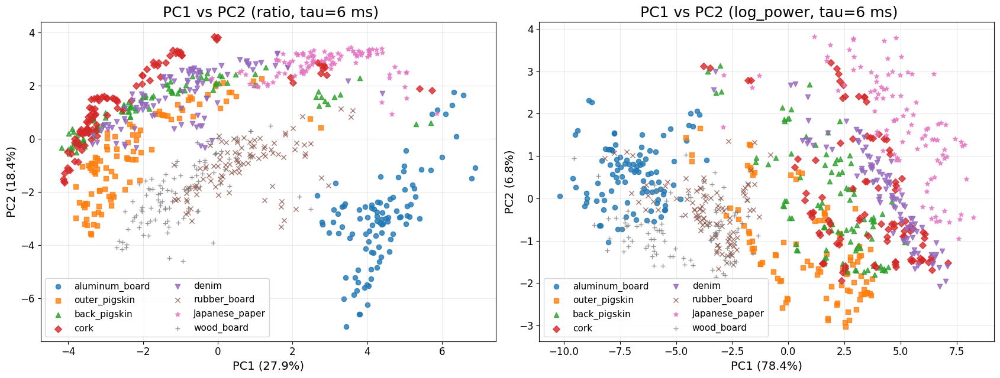

In [10]:
# tau=2.0 ms の特徴量を PCA で2次元表示
PCA_TAU_MS = 6.0
PCA_FEATURES = ["ratio", "log_power"]
PCA_SENSOR_COMBO = "s0+s1+s2"
PCA_MARKERS = ["o", "s", "^", "D", "v", "x", "*", "+"]
PCA_COLORS = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple",
    "tab:brown",
    "tab:pink",
    "tab:gray",
]


def pca_2d(x):
    x = np.asarray(x, dtype=float)
    x = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + EPS)
    _, singular_values, vt = np.linalg.svd(x, full_matrices=False)
    scores = x @ vt[:2].T
    explained = singular_values ** 2
    explained_ratios = explained / (np.sum(explained) + EPS)
    return scores, explained_ratios


def pc_label(component_index, explained_ratios):
    label = f"PC{component_index + 1}"
    if component_index < len(explained_ratios):
        label += f" ({explained_ratios[component_index] * 100:.1f}%)"
    return label


pca_df = band_feature_df[band_feature_df["tau_ms"] == PCA_TAU_MS].copy()
pca_sensor_ids = SENSOR_COMBINATIONS[PCA_SENSOR_COMBO]

fig, axes = plt.subplots(1, len(PCA_FEATURES), figsize=(8.5 * len(PCA_FEATURES), 6.5), squeeze=False)
axes = axes[0]

for ax, feature_name in zip(axes, PCA_FEATURES):
    cols = feature_columns(feature_name, pca_sensor_ids)
    scores, explained_ratios = pca_2d(pca_df[cols].to_numpy())
    labels = pca_df["material"].astype(str).to_numpy()
    unique_labels = list(dict.fromkeys(labels))

    for label_index, label in enumerate(unique_labels):
        mask = labels == label
        ax.scatter(
            scores[mask, 0],
            scores[mask, 1],
            c=PCA_COLORS[label_index % len(PCA_COLORS)],
            marker=PCA_MARKERS[label_index % len(PCA_MARKERS)],
            s=35,
            linewidths=1.0,
            alpha=0.8,
            label=label,
        )

    ax.set_xlabel(pc_label(0, explained_ratios), fontsize=14)
    ax.set_ylabel(pc_label(1, explained_ratios), fontsize=14)
    ax.set_title(f" PC1 vs PC2 ({feature_name}, tau={PCA_TAU_MS:g} ms)", fontsize=18)
    ax.tick_params(labelsize=12)
    ax.grid(True, alpha=0.25)
    if len(unique_labels) <= 12:
        ax.legend(fontsize=11, ncol=2)

plt.tight_layout()
plt.show()


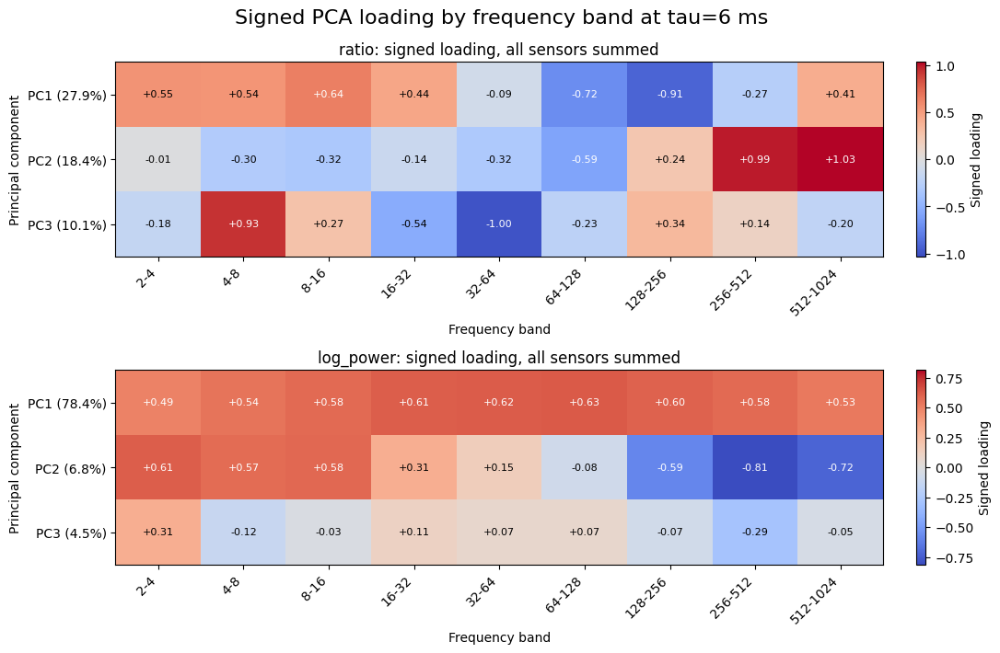

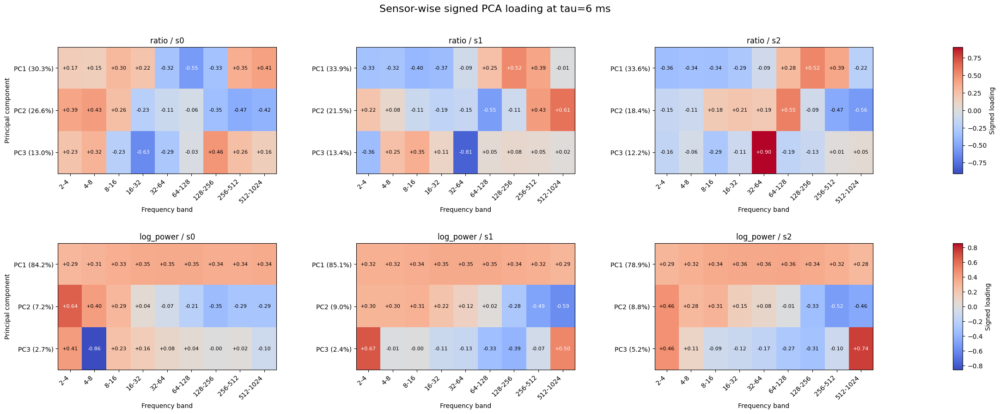

In [11]:
# tau=2.0 ms の PCA loading を周波数帯域ごとにヒートマップ表示
PCA_TAU_MS = 6.0
PCA_FEATURES = ["ratio", "log_power"]
PCA_SENSOR_COMBO = "s0+s1+s2"
N_LOADING_COMPONENTS = 3
BAND_LABELS = [f"{low}-{high}" for low, high in FREQ_BANDS]


def pca_svd_for_loading(x, n_components=N_LOADING_COMPONENTS):
    x = np.asarray(x, dtype=float)
    x = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + EPS)
    _, singular_values, vt = np.linalg.svd(x, full_matrices=False)
    explained = singular_values ** 2
    explained_ratios = explained / (np.sum(explained) + EPS)
    return vt[:n_components], explained_ratios[:n_components]


def signed_loading_by_band(feature_name, sensor_ids):
    cols = []
    band_to_col_indices = []

    for low, high in FREQ_BANDS:
        indices = []
        for sensor_id in sensor_ids:
            col = f"s{sensor_id}_{feature_name}_{low}_{high}Hz"
            indices.append(len(cols))
            cols.append(col)
        band_to_col_indices.append(indices)

    pca_df_for_loading = band_feature_df[band_feature_df["tau_ms"] == PCA_TAU_MS].copy()
    components, explained_ratios = pca_svd_for_loading(pca_df_for_loading[cols].to_numpy())

    loading = np.zeros((components.shape[0], len(FREQ_BANDS)), dtype=float)
    for band_id, indices in enumerate(band_to_col_indices):
        loading[:, band_id] = np.sum(components[:, indices], axis=1)
    return loading, explained_ratios


sensor_ids_for_loading = SENSOR_COMBINATIONS[PCA_SENSOR_COMBO]
fig, axes = plt.subplots(len(PCA_FEATURES), 1, figsize=(11, 3.6 * len(PCA_FEATURES)), squeeze=False)
axes = axes[:, 0]

for ax, feature_name in zip(axes, PCA_FEATURES):
    loading, explained_ratios = signed_loading_by_band(feature_name, sensor_ids_for_loading)
    vmax = np.max(np.abs(loading))
    image = ax.imshow(loading, aspect="auto", cmap="coolwarm", vmin=-vmax, vmax=vmax)

    ax.set_title(f"{feature_name}: signed loading, all sensors summed")
    ax.set_xlabel("Frequency band")
    ax.set_ylabel("Principal component")
    ax.set_xticks(np.arange(len(BAND_LABELS)))
    ax.set_xticklabels(BAND_LABELS, rotation=45, ha="right")
    ax.set_yticks(np.arange(loading.shape[0]))
    ax.set_yticklabels([
        f"PC{i + 1} ({explained_ratios[i] * 100:.1f}%)"
        for i in range(loading.shape[0])
    ])

    for row in range(loading.shape[0]):
        for col in range(loading.shape[1]):
            value = loading[row, col]
            text_color = "white" if abs(value) > 0.55 * vmax else "black"
            ax.text(col, row, f"{value:+.2f}", ha="center", va="center", color=text_color, fontsize=8)

    cbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.04)
    cbar.set_label("Signed loading")

fig.suptitle(f"Signed PCA loading by frequency band at tau={PCA_TAU_MS:g} ms", fontsize=16)
plt.tight_layout()
plt.show()

# 各センサーごとの signed PCA loading をヒートマップ表示
fig, axes = plt.subplots(
    len(PCA_FEATURES),
    4,
    figsize=(22, 4.6 * len(PCA_FEATURES)),
    gridspec_kw={"width_ratios": [1, 1, 1, 0.045], "wspace": 0.48, "hspace": 0.55},
    squeeze=False,
)
heatmap_axes = axes[:, :3]
cbar_axes = axes[:, 3]
last_images = []

for row_id, feature_name in enumerate(PCA_FEATURES):
    row_vmax = 0.0
    row_results = []

    for sensor_id in range(3):
        loading, explained_ratios = signed_loading_by_band(feature_name, [sensor_id])
        row_results.append((sensor_id, loading, explained_ratios))
        row_vmax = max(row_vmax, float(np.max(np.abs(loading))))

    for col_id, (sensor_id, loading, explained_ratios) in enumerate(row_results):
        ax = heatmap_axes[row_id, col_id]
        image = ax.imshow(loading, aspect="auto", cmap="coolwarm", vmin=-row_vmax, vmax=row_vmax)
        last_images.append(image)

        ax.set_title(f"{feature_name} / s{sensor_id}")
        ax.set_xlabel("Frequency band")
        ax.set_ylabel("Principal component" if col_id == 0 else "")
        ax.set_xticks(np.arange(len(BAND_LABELS)))
        ax.set_xticklabels(BAND_LABELS, rotation=45, ha="right")
        ax.set_yticks(np.arange(loading.shape[0]))
        ax.set_yticklabels([
            f"PC{i + 1} ({explained_ratios[i] * 100:.1f}%)"
            for i in range(loading.shape[0])
        ])

        for pc_id in range(loading.shape[0]):
            for band_id in range(loading.shape[1]):
                value = loading[pc_id, band_id]
                text_color = "white" if abs(value) > 0.55 * row_vmax else "black"
                ax.text(band_id, pc_id, f"{value:+.2f}", ha="center", va="center", color=text_color, fontsize=8)

    cbar = fig.colorbar(last_images[-1], cax=cbar_axes[row_id])
    cbar.set_label("Signed loading")

fig.suptitle(f"Sensor-wise signed PCA loading at tau={PCA_TAU_MS:g} ms", fontsize=16)
fig.subplots_adjust(top=0.88, bottom=0.12, left=0.07, right=0.96)
plt.show()


RI/SI files: 2592


,material,files
0,Japanese_paper,324
1,aluminum_board,324
2,back_pigskin,324
3,cork,324
4,denim,324
5,outer_pigskin,324
6,rubber_board,324
7,wood_board,324


,sensor,abs_derivative_rms_scale
0,s0,1.620796
1,s1,2.909883
2,s2,2.279392


,component,component_rms_scale
0,RI,9.156278
1,SI,553.907547


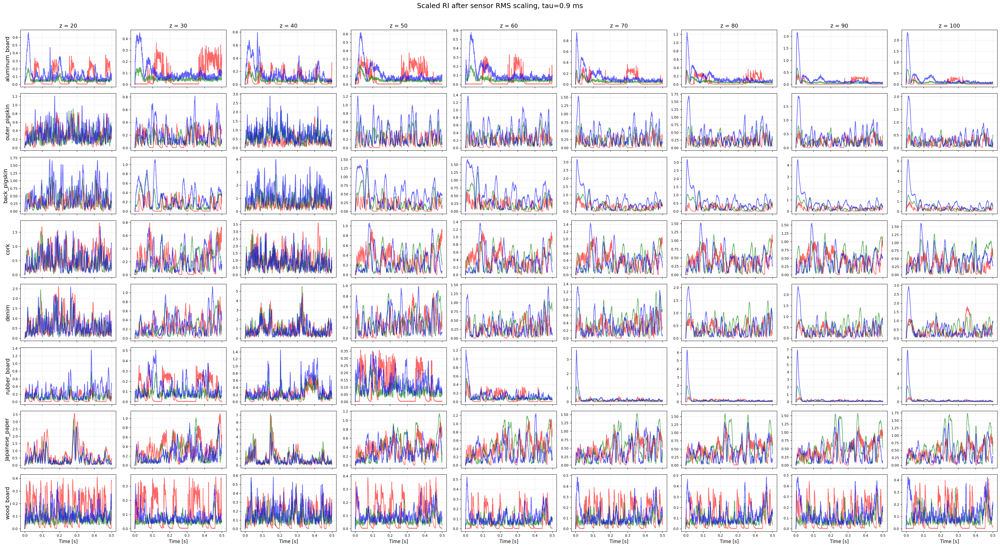

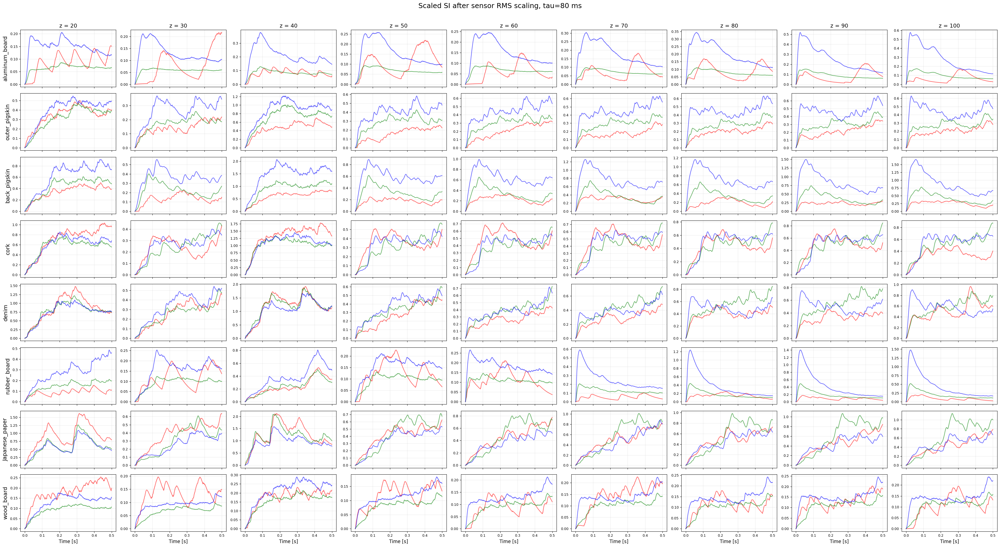

In [12]:
# RI/SI 風フィルタを abs(dF/dt) の後に適用し、センサー間とRI/SI間のスケールを合わせる
RI_TAU_MS = 0.9
SI_TAU_MS = 80.0
RI_SI_BASE_TAU_MS =6.0
RI_SI_FILTERS = {
    "RI": RI_TAU_MS,
    "SI": SI_TAU_MS,
}


def rms_value(x):
    x = np.asarray(x, dtype=float)
    return float(np.sqrt(np.mean(x * x))) if x.size else np.nan


def exp_response_filter(data, dt=dt_data, tau_ms=1.0):
    data = np.asarray(data, dtype=float)
    if tau_ms <= 0:
        return data.copy()

    tau_s = tau_ms * 1e-3
    decay = np.exp(-dt / tau_s)

    if data.ndim == 1:
        out = np.empty_like(data)
        out[0] = data[0]
        for i in range(1, data.shape[0]):
            out[i] = decay * out[i - 1] + data[i]
        return out

    return np.array([
        exp_response_filter(data[s], dt=dt, tau_ms=tau_ms)
        for s in range(data.shape[0])
    ])


def load_abs_derivative_input(file_path_csv, ema_tau_ms=RI_SI_BASE_TAU_MS):
    t_array, raw = read_raw_sample(file_path_csv)
    smoothed = ema_filter(raw, dt=dt_data, tau_ms=ema_tau_ms)
    abs_derivative = abs_derivative_signal(smoothed, t_array, width=DERIVATIVE_WIDTH)
    return t_array, abs_derivative


# 最後のRI/SIセルでは全素材・全速度・全ファイルを使う
ri_si_file_df = collect_all_files()
print(f"RI/SI files: {len(ri_si_file_df)}")
display(ri_si_file_df.groupby("material").size().reset_index(name="files"))


# 1段目: abs(dF/dt) の後に、各センサーのRMSでスケールを合わせる
ri_si_abs_derivative_cache = {}
for _, sample in ri_si_file_df.iterrows():
    file_path_csv = Path(sample["path"])
    t_array, abs_derivative = load_abs_derivative_input(file_path_csv)
    ri_si_abs_derivative_cache[str(file_path_csv)] = {
        "time": t_array,
        "abs_derivative": abs_derivative,
    }

sensor_scale = {}
for sensor_id in range(3):
    values = [item["abs_derivative"][sensor_id] for item in ri_si_abs_derivative_cache.values()]
    sensor_scale[sensor_id] = rms_value(np.concatenate(values)) if values else 1.0
    if not np.isfinite(sensor_scale[sensor_id]) or sensor_scale[sensor_id] == 0:
        sensor_scale[sensor_id] = 1.0

sensor_scale_df = pd.DataFrame([
    {"sensor": f"s{sensor_id}", "abs_derivative_rms_scale": scale}
    for sensor_id, scale in sensor_scale.items()
])
display(sensor_scale_df)

# 2段目: センサー補正後の abs(dF/dt) から RI/SI を作り、RI/SI成分ごとのRMSでスケールを合わせる
ri_si_scaled_cache = {}
component_unscaled_values = {"RI": [], "SI": []}

for file_key, item in ri_si_abs_derivative_cache.items():
    t_array = item["time"]
    abs_derivative = item["abs_derivative"]
    sensor_scaled_derivative = np.array([
        abs_derivative[sensor_id] / sensor_scale[sensor_id]
        for sensor_id in range(abs_derivative.shape[0])
    ])
    ri = exp_response_filter(sensor_scaled_derivative, dt=dt_data, tau_ms=RI_TAU_MS)
    si = exp_response_filter(sensor_scaled_derivative, dt=dt_data, tau_ms=SI_TAU_MS)
    ri_si_scaled_cache[file_key] = {
        "time": t_array,
        "RI_unscaled": ri,
        "SI_unscaled": si,
    }
    component_unscaled_values["RI"].append(ri.reshape(-1))
    component_unscaled_values["SI"].append(si.reshape(-1))

component_scale = {}
for component_name, values in component_unscaled_values.items():
    component_scale[component_name] = rms_value(np.concatenate(values)) if values else 1.0
    if not np.isfinite(component_scale[component_name]) or component_scale[component_name] == 0:
        component_scale[component_name] = 1.0

component_scale_df = pd.DataFrame([
    {"component": component_name, "component_rms_scale": scale}
    for component_name, scale in component_scale.items()
])
display(component_scale_df)

for file_key, item in ri_si_scaled_cache.items():
    item["RI"] = item["RI_unscaled"] / component_scale["RI"]
    item["SI"] = item["SI_unscaled"] / component_scale["SI"]

# スケール補正後の RI/SI 波形を素材・速度ごとに表示
for filter_name, tau_ms in RI_SI_FILTERS.items():
    fig, axes = plt.subplots(
        len(material_labels),
        len(tracing_speed),
        figsize=(4 * len(tracing_speed), 2.5 * len(material_labels)),
        squeeze=False,
        sharex=True,
        sharey=False,
    )

    for i, material in enumerate(material_labels):
        for j, speed in enumerate(tracing_speed):
            ax = axes[i, j]
            file_rows = ri_si_file_df[
                (ri_si_file_df["material"] == material) &
                (ri_si_file_df["speed"] == speed)
            ].head(NUM_SAMPLE)

            if len(file_rows) == 0:
                ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes)
            else:
                for _, row in file_rows.iterrows():
                    file_key = str(Path(row["path"]))
                    result = ri_si_scaled_cache[file_key]
                    t_array = result["time"]
                    filtered = result[filter_name]
                    for sensor_id in range(3):
                        ax.plot(t_array, filtered[sensor_id], color=clr[sensor_id], alpha=0.6)

            if i == 0:
                ax.set_title(f"z = {speed}", fontsize=14)
            if j == 0:
                ax.set_ylabel(material, fontsize=14)
            if i == len(material_labels) - 1:
                ax.set_xlabel("Time [s]", fontsize=12)
            ax.tick_params(labelsize=9)
            ax.grid(True, alpha=0.25)

    fig.suptitle(
        f"Scaled {filter_name} after sensor RMS scaling, tau={tau_ms:g} ms",
        fontsize=18,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


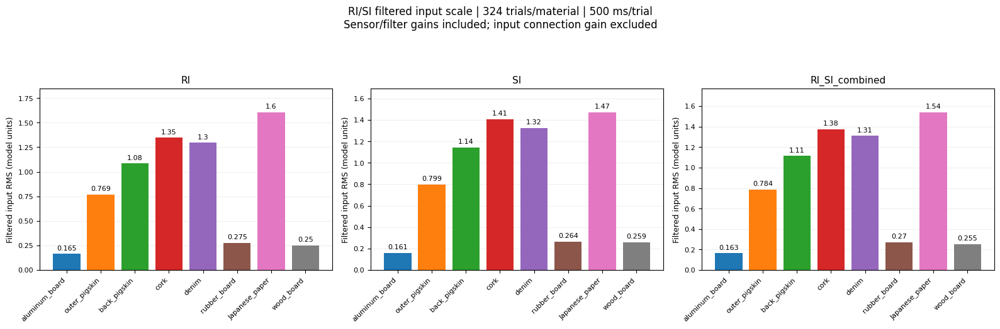

,material,n_trials,RI,SI,RI_SI_combined
0,aluminum_board,324,0.164818,0.161327,0.163082
1,outer_pigskin,324,0.769283,0.799299,0.784434
2,back_pigskin,324,1.084434,1.142581,1.113887
3,cork,324,1.346506,1.405266,1.376200
4,denim,324,1.295460,1.323817,1.309715
5,rubber_board,324,0.274666,0.264287,0.269526
6,Japanese_paper,324,1.604866,1.471563,1.539658
7,wood_board,324,0.250423,0.258832,0.254662


In [13]:
# 全8素材・全324試行のRI/SI入力スケール（直前のセルで計算した値を使用）
# 素材ごとに全試行・3センサー・全時刻の二乗平均平方根を計算する。
# RI_SI_combinedはRIとSIの6チャネルをまとめたRMS。RI+SIの加算ではない。
# センサー・フィルタのスケール補正を含み、入力結合gainは含まない。
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if "ri_si_scaled_cache" not in globals() or "ri_si_file_df" not in globals():
    raise RuntimeError("直前のRI/SIフィルタ計算セルを実行してから、このセルを実行してください。")

scale_materials = ["aluminum_board", "outer_pigskin", "back_pigskin", "cork", "denim",
                   "rubber_board", "Japanese_paper", "wood_board"]
scale_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
                "tab:brown", "tab:pink", "tab:gray"]
scale_rows = []
for material in scale_materials:
    file_rows = ri_si_file_df.loc[ri_si_file_df["material"] == material]
    if len(file_rows) != 324 or file_rows["path"].astype(str).nunique() != 324:
        raise ValueError(f"{material}: 重複のない324試行が必要です（現在{len(file_rows)}行）。")
    sum_squares = {"RI": 0.0, "SI": 0.0}
    n_values = {"RI": 0, "SI": 0}
    for csv_path in file_rows["path"]:
        result = ri_si_scaled_cache[str(Path(csv_path))]
        for name in ["RI", "SI"]:
            values = np.asarray(result[name], dtype=float)
            if values.shape != (3, 5000) or not np.isfinite(values).all():
                raise ValueError(f"{material}: {csv_path}: {name}の形または値が不正です。")
            sum_squares[name] += float(np.einsum("ij,ij->", values, values))
            n_values[name] += values.size
    scale_rows.append({
        "material": material,
        "n_trials": len(file_rows),
        "RI": np.sqrt(sum_squares["RI"] / n_values["RI"]),
        "SI": np.sqrt(sum_squares["SI"] / n_values["SI"]),
        "RI_SI_combined": np.sqrt(sum(sum_squares.values()) / sum(n_values.values())),
    })

filtered_input_scale_df = pd.DataFrame(scale_rows)
fig, axes = plt.subplots(1, 3, figsize=(16, 5.3))
for ax, name in zip(axes, ["RI", "SI", "RI_SI_combined"]):
    heights = filtered_input_scale_df[name].to_numpy()
    bars = ax.bar(np.arange(8), heights, color=scale_colors)
    ax.bar_label(bars, labels=[f"{v:.3g}" for v in heights], padding=3, fontsize=8)
    ax.set_xticks(np.arange(8), scale_materials, rotation=45, ha="right")
    ax.set_title(name, fontsize=11)
    ax.set_ylabel("Filtered input RMS (model units)", fontsize=9)
    ax.set_ylim(0, max(float(heights.max()) * 1.15, 0.1))
    ax.tick_params(labelsize=8)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle(
    "RI/SI filtered input scale | 324 trials/material | 500 ms/trial\n"
    "Sensor/filter gains included; input connection gain excluded",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0, 1, 0.90))

# 図と集計表はノートブック内に表示し、外部ファイルには保存しない。
plt.show()
display(filtered_input_scale_df)
